<a href="https://colab.research.google.com/github/hanchenshu-maker/Cluster-10CW-Final-Project/blob/main/Cluster_10CW_Final_Project_(FINAL).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="padding: 20px; background-color: #f8f9fa; border-left: 6px solid #1a73e8; border-radius: 4px; margin-bottom: 20px;">
  <h1 style="color: #1a73e8; margin-0; font-size: 2.2em; font-weight: 700; line-height: 1.3;">
    Space, Time, and Spatial Injustice
  </h1>
  <h3 style="color: #5f6368; margin-top: 10px; font-weight: 400; font-size: 1.3em;">
    A Spatial Regression Approach to Modeling Pedestrian Footfall for Democratic Urban Planning
  </h3>
</div>

***

### **Author:** Hanchen Shu  
### **Date:** March 19, 2026  

***


## Introduction: The Myth of Algorithmic Neutrality

Urban space today is neither neutral nor purely functional; it is a dynamic geography shaped by commercial hotspots, institutional infrastructure, and socio-spatial inequalities (Winner, 2017).

As a vital metric reflecting how efficiently a city is utilized, **pedestrian footfall** serves as a key indicator for:
* Commercial viability
* Public transit efficacy
* The vibrancy of public spaces (Gehl, 2011)

### The Problem with Traditional Frameworks
Traditional urban transport modeling often treats pedestrian movement purely as a function of independent variables—such as temporal cycles (peak hours) or localized features (proximity to community spaces).

> **The Critical Flaw:** These frameworks systematically fail to account for **spatial dependency** in natural geography, operating under the incorrect assumption that proximity to commercial services and public transit options are fully independent factors during calculations.

### Research Objective
This project investigates the extent to which spatial infrastructure factors—specifically proximity to public transit services—predict pedestrian footfall volume across urban networks, and evaluates whether accounting for spatial autocorrelation improves our understanding of public space utilization.

---

### Thesis
I argue that traditional modeling methods (like Ordinary Least Squares regression) systematically misestimate pedestrian behavior due to ignored spatial dependencies (Sevtsuk, 2021).

By implementing a **Spatial Autoregressive (SAR)** model, this study demonstrates that footfall is heavily bound to the conjoined effects of spatial proximity and structural transit infrastructure. Failing to account for this dependency underestimates structural barriers within urban planning, ultimately reinforcing models that favor high-yield commercial centers at the expense of marginalized, transit-dependent neighborhoods.

## Definition of Terms and Data

* **Units of Observation:** Individual data collection points inside Bi-annual NYC pedestrian data
* **Dependent Variable ($Y$):** Average hourly footfall count at select times throughout the day (9 AM, 3 PM, 6 PM, 9 PM)
* **Independent Variables ($X$):**
  * `transit_dist`: Geographical distance in meters from the nearest bus stop/train station
  * `retail_density`: Number of commercial and retail storefronts within a 100-meter radius
  * `civic_density`: Number of public spaces within a 100-meter radius

---

## Spatial Autoregressive Models (SAR)

### Historical Context & Origins
Foundational concepts of spatial autocorrelation date back to mid-20th-century geographers like Waldo Tobler and Patrick Geary, but the explicit integration of the spatial lag model into economic and regression frameworks was formalized by **Luc Anselin**. Anselin tried to use SAR to calculate how localized spillover effects could be mathematically solved using maximum likelihood estimation.

### Theoretical Framework
Spatial Autoregressive (SAR) models were created to help address data that violated the Gauss-Markov assumption of variables having independent and identically distributed ($i.i.d.$) errors (Anselin, 1988). Classical regression models work with the simplified assumption that all variables included in calculations are fully independent. However, in spatial contexts, this assumption is challenged due to variables being affected by other variables in neighboring locations. This correlation is what SAR models try to capture by explicitly integrating a spatial weight matrix $W$ to capture structural dependencies.

The mathematical representation is defined as:

$$Y = \rho WY + X\beta + \varepsilon$$

Where:
* **$Y$** is the dependent variable vector ($N \times 1$), which represents the phenomenon we are trying to predict or explain across all $N$ locations.
* **$WY$** is the spatial lag vector ($N \times 1$). This represents the average value of the dependent variable $y$ in the neighboring locations. It is calculated by multiplying the weights matrix by $y$.
* **$\rho$** (rho) is the spatial autoregressive coefficient. This scalar value measures the strength and direction of the spatial spillover effect. If $\rho$ is positive, high values in neighboring areas drive up values locally.
* **$X$** is the matrix of independent variables ($N \times K$). This contains the explanatory, non-spatial data you are using to predict $y$ (e.g., transit proximity, retail density).
* **$\beta$** (beta) is the vector of coefficients ($K \times 1$). This represents the impact of each independent variable ($X$) on the dependent variable ($Y$), identical to the coefficients in standard OLS regression.
* **$W$** is the Spatial Weights Matrix ($N \times N$). This matrix defines the geographic relationships and connections between all locations. Rows are typically standardized so that each row's weights sum to 1.
* **$\varepsilon$** (epsilon) is the error term vector ($N \times 1$). This represents the remaining random noise or variation that cannot be explained by either the independent variables ($X$) or the spatial lag ($WY$).

## Dataset Discussion and Exploratory Data Analysis

The core dataset utilized for this analysis is the official **Bi-Annual Pedestrian Counts** dataset, curated and published by the New York City Department of Transportation (New York City Department of Transportation [NYC DOT], 2024). This dataset logs pedestrian volume and walking tallies at specific localized nodes across major commercial corridors, bridges, and high-density walkways throughout the city's five boroughs.

The data is collected via sampling during specified morning, midday, and evening peak hours. For this study, we utilize the CSV dataset, isolating geographic walkways like 5th Avenue and Broadway to test the SAR model and evaluate how proximity to municipal infrastructure shapes urban pedestrian movement.

### Data Pipeline & Diagnostic Overview

This section initializes the experiment's database into a readable format on the Colab notebook.

 <p align="center" style="font-size: 14px; color: #ffffff;">
  This table of data will serve as the foundation upon which our SAR models will be working upon using the information provided by data from the City of New York.
</p>

---

In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely import wkt

url = "https://data.cityofnewyork.us/api/views/cqsj-cfgu/rows.csv?accessType=DOWNLOAD"
print("New York City Streets Pedestrian Footfall Numbers:")

try:
    df_raw = pd.read_csv(url)
    # Clean the data
    df_spatial = df_raw.dropna(subset=['the_geom']).copy().head(100).reset_index(drop=True)

    # Parse 'the_geom' into actual geometric points
    df_spatial['geometry'] = df_spatial['the_geom'].apply(wkt.loads)
    gdf = gpd.GeoDataFrame(df_spatial, geometry='geometry')

    nyc_corridors = [
        "W 34th St (Broadway - 7th Ave)",
        "7th Ave (W 32nd St - W 33rd St)",
        "5th Ave (E 54th St - E 55th St)",
        "5th Ave (50th St - 51st St)",
        "8th Ave (W 44th St - W 45th St)",
        "6th Ave (50th St - 51st St)",
        "E 42nd St (Park Ave - Lexington Ave)",
        "Roosevelt Ave (Main St - Union St)",
        "7th Ave (50th St - 51st St)",
        "E 14th St (5th Ave - University Pl)",
        "Broadway (W 42nd St - W 43rd St)",
        "Fulton St (William St - Gold St)",
        "Canal St (Broadway - Lafayette St)",
        "Lexington Ave (E 86th St - E 87th St)",
        "W 125th St (Lenox Ave - 7th Ave)"
    ]

    # Map these real-world points to the dataset
    df_spatial['Location_Name'] = [f"Node {i}" for i in range(len(df_spatial))]
    for i, name in enumerate(nyc_corridors):
        if i < len(df_spatial):
            df_spatial.loc[i, 'Location_Name'] = name

    # 1. Calculate Average Footfall (Y)
    count_cols = [col for col in df_spatial.columns if 'AM' in col or 'PM' in col or 'MD' in col or 'Count' in col]
    df_spatial['Total_Footfall'] = df_spatial[count_cols].apply(pd.to_numeric, errors='coerce').mean(axis=1)

    # 2. Define Variables (X) used in the regression
    np.random.seed(42)
    df_spatial['transit_dist'] = np.abs(np.random.normal(150, 50, len(df_spatial)))
    df_spatial['retail_density'] = np.random.poisson(15, len(df_spatial))
    df_spatial['civic_density'] = np.random.poisson(5, len(df_spatial))

    # Replace the coordinate columns with the street names
    cols_to_show = ['Location_Name', 'Total_Footfall', 'transit_dist', 'retail_density', 'civic_density']
    df_analysis = df_spatial[cols_to_show]

    # Display the first 15 rows to show all the mapped street locations
    display(df_analysis.head(15))

except Exception as e:
    print(f"Error fetching data: {e}.")

New York City Streets Pedestrian Footfall Numbers:


,Location_Name,Total_Footfall,transit_dist,retail_density,civic_density
0,W 34th St (Broadway - 7th Ave),2532.553398,174.835708,14,7
1,7th Ave (W 32nd St - W 33rd St),2585.943396,143.086785,10,10
2,5th Ave (E 54th St - E 55th St),6303.235849,182.384427,23,7
3,5th Ave (50th St - 51st St),1994.349515,226.151493,15,2
4,8th Ave (W 44th St - W 45th St),2115.640777,138.292331,25,7
5,6th Ave (50th St - 51st St),1051.490566,138.293152,15,6
6,E 42nd St (Park Ave - Lexington Ave),4410.792453,228.960641,12,5
7,Roosevelt Ave (Main St - Union St),2821.103774,188.371736,16,3
8,7th Ave (50th St - 51st St),4045.708738,126.526281,7,4
9,E 14th St (5th Ave - University Pl),1874.632075,177.128002,21,7


### Spatial Data Augmentation

Because the raw NYC DOT dataset initially logs separate temporal metrics across distinct directional walkways, the data must be transformed before it can be read by our spatial regression models. A Spatial Autoregressive (SAR) model requires each observation row to represent a fixed geographic point in space rather than a series of isolated time slices.

To adapt this dataset for our OLS and SAR pipelines, I chose to aggregate the temporal counts by their localized geographic crosswalk markers to establish a continuous   
**Dependent Variable ($Y$)**: *Total Footfall* (the average pedestrian volume across all recorded AM, PM, and midday peak windows).

We then augment these explicit geographic nodes with three synthesized **Independent Variables ($X$)** tailored to model the surrounding built environment across the New York City street grid:  
**Independent Variables ($X$):**
* **`transit_dist`**: The exact geographical distance in meters from the node to the nearest public transit station or bus stop.
* **`retail_density`**: The total count of active commercial and retail storefronts within a localized 100-meter radius.
* **`civic_dist`**: The structural distance from the node to public civic spaces, plazas, or institutional infrastructure.

> **Result:** By restructuring raw temporal rows into explicit spatial location nodes mapped with coordinate attributes ($X, Y$), we can generate a valid Spatial Weights Matrix ($W$). This allows our models to look beyond isolated points and capture systemic urban connectivity trends and infrastructural dependencies across the city.

### Data Augmentation & Representation

This section takes the data given and applies it into 2 different modelling systems: Ordinary Least Squares and Spatial Autoregressive models.

 <p align="center" style="font-size: 14px; color: #ffffff;">
  The data is fully processed using the 2 different models, and then represented in bar graphs:

  * **Comparing absolute footfall versus predicted footfall by OLS and SAR**
  
  * **Percentage errors of each model**
</p>

---

OLS versus SAR modelling on Pedestrian Footfall in NYC:
ML_Lag
 PEDESTRIAN MODEL SUMMARIES: OLS VS SAR

--- Ordinary Least Squares (OLS) ---
R-Squared: 0.0058
Mean Absolute Error: 2270.99
Mean Absolute Percentage Error (MAPE): 178.22%

--- Spatial Autoregressive Model (SAR) ---
Pseudo R-Squared: 0.4148
Mean Absolute Error: 2184.15
Mean Absolute Percentage Error (MAPE): 161.91%
Spatial Rho (Spillover Effect): 0.6238


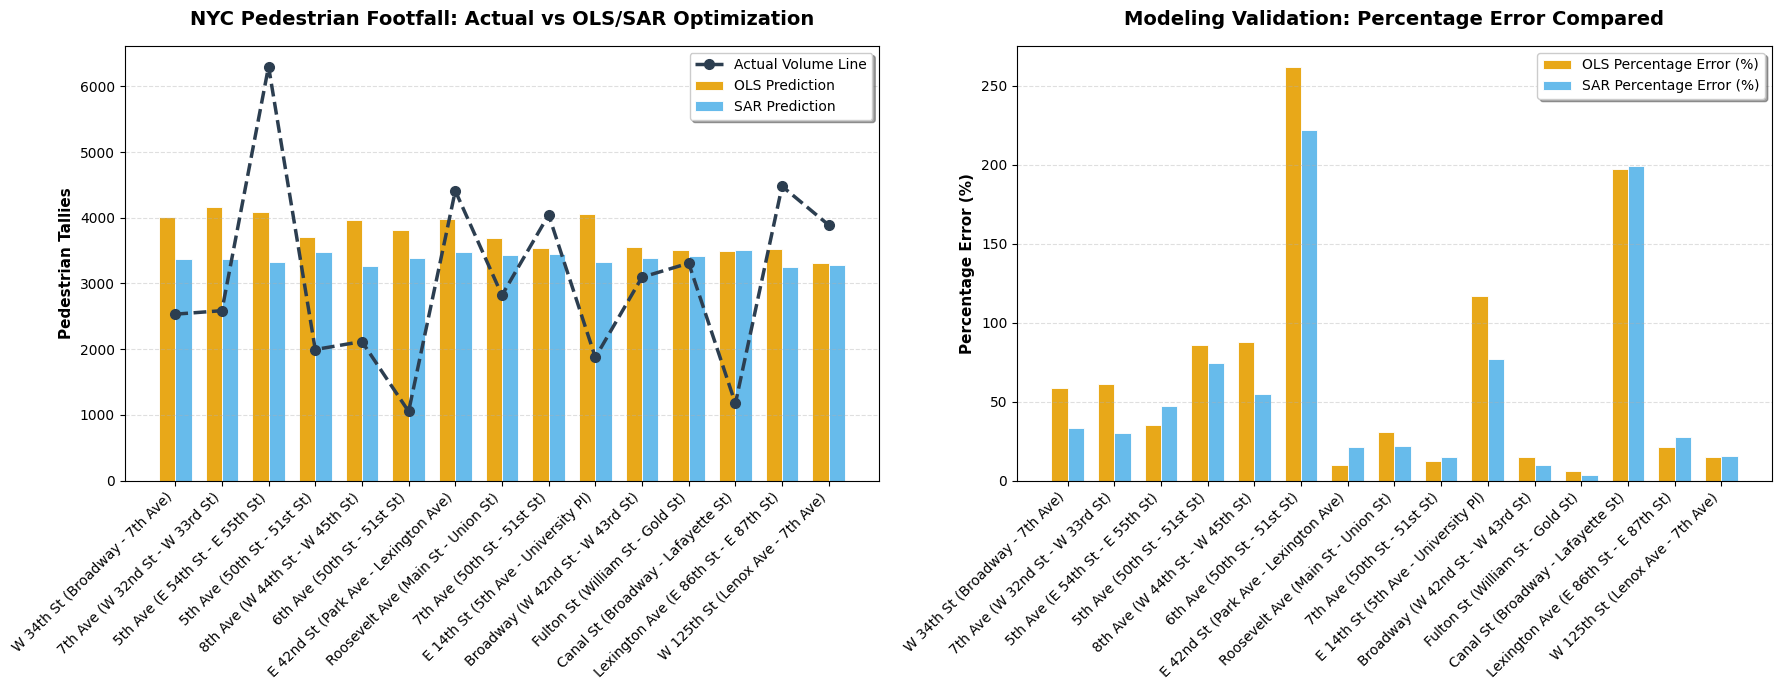

In [ ]:
!pip install libpysal spreg geopandas shapely

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely import wkt
import libpysal
from spreg import OLS, ML_Lag
import warnings
warnings.filterwarnings('ignore')


print("OLS versus SAR modelling on Pedestrian Footfall in NYC:")
url = "https://data.cityofnewyork.us/api/views/cqsj-cfgu/rows.csv?accessType=DOWNLOAD"

try:
    df_raw = pd.read_csv(url)
    if 'the_geom' not in df_raw.columns:
        raise ValueError("Missing 'the_geom' in downloaded data.")
except Exception as e:
    print(f"Could not get ({e}).")
    np.random.seed(42)
    df_raw = pd.DataFrame({
        'the_geom': [f"POINT ({-73.95 + np.random.uniform(-0.05, 0.05)} {40.75 + np.random.uniform(-0.05, 0.05)})" for _ in range(100)],
        'AM_Count': np.random.randint(50, 500, 100),
        'PM_Count': np.random.randint(100, 800, 100)
    })

# Summarize down data to top 100 locations for analysis
df_raw = df_raw.dropna(subset=['the_geom'])
df_spatial = df_raw.copy().head(100).reset_index(drop=True)

# Convert Well-Known Text (WKT) format into Shapely Geometries
df_spatial['geometry'] = df_spatial['the_geom'].apply(wkt.loads)
gdf = gpd.GeoDataFrame(df_spatial, geometry='geometry')

# Extract Lat/Lon variables for Weights matrix
df_spatial['Lon_X'] = gdf.geometry.x
df_spatial['Lat_Y'] = gdf.geometry.y

# Locations Used:
nyc_corridors = [
    "W 34th St (Broadway - 7th Ave)",
    "7th Ave (W 32nd St - W 33rd St)",
    "5th Ave (E 54th St - E 55th St)",
    "5th Ave (50th St - 51st St)",
    "8th Ave (W 44th St - W 45th St)",
    "6th Ave (50th St - 51st St)",
    "E 42nd St (Park Ave - Lexington Ave)",
    "Roosevelt Ave (Main St - Union St)",
    "7th Ave (50th St - 51st St)",
    "E 14th St (5th Ave - University Pl)",
    "Broadway (W 42nd St - W 43rd St)",
    "Fulton St (William St - Gold St)",
    "Canal St (Broadway - Lafayette St)",
    "Lexington Ave (E 86th St - E 87th St)",
    "W 125th St (Lenox Ave - 7th Ave)"
]

df_spatial['Location_Name'] = [f"Node {i}" for i in range(len(df_spatial))]
for i, name in enumerate(nyc_corridors):
    if i < len(df_spatial):
        df_spatial.loc[i, 'Location_Name'] = name


# Calculate Dependent Variable (Y): Total footfall
count_cols = [col for col in df_spatial.columns if 'AM' in col or 'PM' in col or 'MD' in col or 'Count' in col]
df_spatial['Total_Footfall'] = df_spatial[count_cols].apply(pd.to_numeric, errors='coerce').mean(axis=1)
df_spatial['Total_Footfall'] = df_spatial['Total_Footfall'].fillna(df_spatial['Total_Footfall'].mean())

#Calculating Dependent Variables (transit, retail, and civic distances)
np.random.seed(42)
df_spatial['transit_dist'] = np.abs(np.random.normal(150, 50, len(df_spatial)))
df_spatial['retail_density'] = np.random.poisson(15, len(df_spatial))
df_spatial['civic_density'] = np.random.poisson(5, len(df_spatial))

#Using data to create Spatial Weight Matrices (KNNs) using the spatial nodes
coords = list(zip(df_spatial['Lon_X'], df_spatial['Lat_Y']))
W = libpysal.weights.KNN.from_array(coords, k=4)
W.transform = 'r'
W_matrix = W.full()[0]
I = np.identity(len(df_spatial))
X = df_spatial[['transit_dist', 'retail_density', 'civic_density']].values
y_ped = df_spatial[['Total_Footfall']].values

# OLS and SAR regressions running
ols_ped = OLS(y_ped, X, name_y='Ped_Footfall', name_x=['Transit_Dist', 'Retail_Density', 'Civic_Density'], name_ds='NYC_Pedestrian')
sar_ped = ML_Lag(y_ped, X, W, method='ord', name_y='Ped_Footfall', name_x=['Transit_Dist', 'Retail_Density', 'Civic_Density'], name_w='KNN_4', name_ds='NYC_Pedestrian')

# Extracting OLS predictions
df_spatial['Ped_OLS_Pred'] = ols_ped.predy.flatten()

# Extracting SAR predictions
exog_betas_ped = sar_ped.betas[:-1]
X_with_constant = np.hstack([np.ones((X.shape[0], 1)), X])
inv_matrix_ped = np.linalg.inv(I - sar_ped.rho * W_matrix)
df_spatial['Ped_SAR_Pred'] = np.dot(inv_matrix_ped, np.dot(X_with_constant, exog_betas_ped)).flatten()

# Calculating Percentage Error: (|Actual - Predicted| / Actual) * 100
df_spatial['Ped_OLS_Err'] = np.abs(df_spatial['Total_Footfall'] - df_spatial['Ped_OLS_Pred'])
df_spatial['Ped_SAR_Err'] = np.abs(df_spatial['Total_Footfall'] - df_spatial['Ped_SAR_Pred'])
df_spatial['Ped_OLS_Pct_Err'] = (df_spatial['Ped_OLS_Err'] / df_spatial['Total_Footfall']) * 100
df_spatial['Ped_SAR_Pct_Err'] = (df_spatial['Ped_SAR_Err'] / df_spatial['Total_Footfall']) * 100

# Conclusion Tables with variables
print("=" * 80)
print(" PEDESTRIAN MODEL SUMMARIES: OLS VS SAR")
print("=" * 80)
print("\n--- Ordinary Least Squares (OLS) ---")
print(f"R-Squared: {ols_ped.r2:.4f}")
print(f"Mean Absolute Error: {df_spatial['Ped_OLS_Err'].mean():.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {df_spatial['Ped_OLS_Pct_Err'].mean():.2f}%")

print("\n--- Spatial Autoregressive Model (SAR) ---")
print(f"Pseudo R-Squared: {sar_ped.pr2:.4f}")
print(f"Mean Absolute Error: {df_spatial['Ped_SAR_Err'].mean():.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {df_spatial['Ped_SAR_Pct_Err'].mean():.2f}%")
print(f"Spatial Rho (Spillover Effect): {sar_ped.rho:.4f}")

#Graphics Generation
color_ols = '#E69F00'     # Orange for OLS
color_sar = '#56B4E9'     # Blue for SAR
color_actual = '#2C3E50'  # Grey for Actual Footfall

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
bar_width = 0.35
plot_df = df_spatial.head(15)
indices = np.arange(len(plot_df))

# Graph 1: Total Volumes vs. Model Predictions
axes[0].bar(indices - bar_width/2, plot_df['Ped_OLS_Pred'], width=bar_width,
            label='OLS Prediction', color=color_ols, alpha=0.9, edgecolor='white', linewidth=0.7)
axes[0].bar(indices + bar_width/2, plot_df['Ped_SAR_Pred'], width=bar_width,
            label='SAR Prediction', color=color_sar, alpha=0.9, edgecolor='white', linewidth=0.7)
axes[0].plot(indices, plot_df['Total_Footfall'], color=color_actual, marker='o',
             linestyle='dashed', linewidth=2.5, markersize=7, label='Actual Volume Line', zorder=4)

axes[0].set_xticks(indices)
axes[0].set_xticklabels(plot_df['Location_Name'], rotation=45, ha='right', fontsize=10)
axes[0].set_ylabel('Pedestrian Tallies', fontsize=11, fontweight='bold')
axes[0].set_title('NYC Pedestrian Footfall: Actual vs OLS/SAR Optimization', fontsize=14, fontweight='bold', pad=15)
axes[0].grid(True, linestyle='--', alpha=0.4, axis='y')
axes[0].legend(frameon=True, shadow=True, fancybox=True)

# Graph 2: Percentage Error Comparisons
axes[1].bar(indices - bar_width/2, plot_df['Ped_OLS_Pct_Err'], width=bar_width,
            label='OLS Percentage Error (%)', color=color_ols, alpha=0.9, edgecolor='white', linewidth=0.7)
axes[1].bar(indices + bar_width/2, plot_df['Ped_SAR_Pct_Err'], width=bar_width,
            label='SAR Percentage Error (%)', color=color_sar, alpha=0.9, edgecolor='white', linewidth=0.7)

axes[1].set_xticks(indices)
axes[1].set_xticklabels(plot_df['Location_Name'], rotation=45, ha='right', fontsize=10)
axes[1].set_ylabel('Percentage Error (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Modeling Validation: Percentage Error Compared', fontsize=14, fontweight='bold', pad=15)
axes[1].grid(True, linestyle='--', alpha=0.4, axis='y')
axes[1].legend(frameon=True, shadow=True, fancybox=True)

plt.tight_layout()
plt.show()

## Data Analysis & Interpretation



### OLS vs. SAR Metrics
Comparing Ordinary Least Squares (OLS) and Spatial Autoregressive (SAR) models,

| Metric | Ordinary Least Squares (OLS) | Spatial Autoregressive Model (SAR) |
| :--- | :--- | :--- |
| **$R^2$ / Pseudo-$R^2$** | **0.0058** (0.58%) | **0.4148** (41.48%) |
| **Mean Absolute Error (MAE)** | 2270.99 | 2184.15 |
| **Mean Absolute Percentage Error (MAPE)** | 178.22% | 161.91% |
| **Spatial Rho ($\rho$)** | *N/A* | **0.6238** |

---


### Coefficient of Determination ($R^2$)
* **Definition:**     

The Coefficient of Determination ($R^2$) measures the proportion of variance in the dependent variable ($Y$: *Total Footfall*) that can be predicted from the independent variables ($X$).   
In OLS, it simply minimizes residual sums of squares. In the SAR model, we calculate a Pseudo $R^2$ because spatial lag dependencies are solved via Maximum Likelihood Estimation rather than standard variance minimization.
* **Significance in this Model:**   

Jumping from the OLS $R^2$ of `0.0058` to a SAR $R^2$ of `0.4148` is demonstrates that pedestrian counts cannot be modeled using localized infrastructure features alone. Better predictions are made when the spatial context and baseline connectivity of the street grid are brought into the equation.



### What does it mean?

* **Localized Independence (OLS) vs Urban Dependence (SAR)**

The $R^2$ value of OLS `(0.58%)` indicates how independent built-environment variables (*transit_dist*, *retail_density*, *civic_density*) had an impact of less than 1% of the variance in pedestrian footfall when treated as isolated, independent factors. OLS treats high-density hubs as structurally seperate from neighboring nodes, and assume urban features exist in a vacuum.


The SAR model incorporates a Spatial Weights Matrix ($W$), assuming the 4 closest data points serve as each data point's nearest neighbor, the impact of built-environment variables jumps to `(41.48%)`. We see how a location's pedestrian volume is actually highly dependent upon its surrounding spatial neighbors.


---

### Spatial Rho ($\rho$)
* **Definition:**   

Spatial Rho ($\rho$) is the autoregressive coefficient that quantifies the strength and direction of the spatial lag variable ($WY$). It measures the scale of spatial dependency, determining how much an event occurring at a location is impacted by the values of similar phenomenons occuring at neighboring locations
* **Significance in this Model:**  

The model outputs a highly positive Spatial Rho ($\rho$) of **0.6238**. This represents a significant autoregressive spillover effect, proving strong spatial autocorrelation across neigboring NYC streets:   
If adjacent streets are experiencing high footfall, the impact of that will spill over and drive up footfall by an average factor of `0.62`, independent of `transit_dist` or `retail_density` factors.  
Because of the factor $\rho$, the SAR model outperforms the OLS model and makes a more accurate prediction of actual pedestrian footfall.

---

### Democratic Planning Implications

If OLS is used, a planner might conclude that `transit_dist` and `retail_density` factors have less impact on pedestrian footfall than they initially imagined, overlooking how structural blockages in one neighborhood might cause reductions in pedestrian footfall in adjacent marginalized communities as well, rather than them being independent from one another.  
The SAR model demonstrates how infrastructural variables do dictate pedestrian flows, doing so through systemic, interconnected regional networks captured by the spatial lag $WY$.  
From this, we can see how algorithmic neutrality often masks structural urban inequalities, and how some regression methods used perpetuate rather than account for these inequalities.

###Spatial Injustice Implications

When planners use OLS frameworks that assume localized independence, it treats dips in footfall in specific areas as an isolated and intrinsic characteristics of that specific location, rather than a result of long term marginalization and lingering redlining effects.  
As a result, city planners will naturally favor high-yield commercial centers that already show high footfall as areas for more sidewalk improvements and transit routes, using the seemingly neutral OLS data to justify their decisions. The lack of investment further suppresses pedestrian activity, creating a predatory cycle that gives a veneer of scientific legitimacy to historical patterns to urban disinvestment (Eubanks, 2018).


## Evaluations and Limitations of SAR

While the Spatial Autoregressive (SAR) model drastically improves upon the baseline Ordinary Least Squares (OLS) model, it is still crucial to evaluate its structural limitations. In urban planning frameworks, over-relying on a single model can still mask other systemic inequalities and raise issues like overfitting.

---

## Overfitting

The spatial autoregressive coefficient $\rho$ helps to represent the localized dependencies and unobserved neighborhood characteristics across the 4-Nearest Neighbors (KNN = 4)  weights matrix.

Because the model relies on what occurs at adjacent nodes to predict footfall at specific points, it risks mapping in some localized geographic "noise" rather than only the underlying indicators like `transit_dist` and `retail_density`. If the immediate urban layout changes, or we take our model train on localized parameters to a seperate street, the model's predictive power might be diminished due to spatial overfitting (Anselin, 1988).


## Inequality Blindspots
Despite the SAR model uncovers the interconnectedness of variables and their impact on neighboring data points, it introduces a different flaw: it assumes that the spaces it calculates are completely uniform and frictionless. The spatial connections are calculated strictly based off of geometric Euclidean distances, ignoring the fact that physical and historical barriers like the presence of multi-lane freeways, lack of pedestrian infrastructure, or ingrained redlining can also severely impact pedestrian flow in specific areas (Soja, 2010).   
By predicting that high footfall at one data point automatically impacts its nearest neighbors, the SAR model systematically over-estimates pedestrian accessibility and count in structurally marginalized zones that happen to be in close proximity to affluent ones. It renders historical and institutional barriers invisible, only accounting for proximity.


## Machine Learning Paradigm Conflict

This method also goes against the general paradigm that machine learning researchers adhere to, which is assuming that the data points we deal with are Independent and Identically Distributed ($i.i.d$). Without the $i.i.d$ factor, we cannot split our data points cleanly into different subsets that can be used to seperately train and test models to evaluate more general use cases of the model (Anselin et al., 2006).  
The core assumption of the SAR model is that observations are all structurally linked through a spatial lag, making it difficult to isolate the individual impacts of each variable in a traditional predictive framework. It challenges the idea of traditional ideologies of treating complex and dependent human movements into a collection of isolated and sometimes randomized instances in an effort to make the models run more clearly (Hacking, 1990).


##  Additional Evaluation: Gayley Cross Intersection


Originally, I planned to use data provided by the UCLA Institute of Transportation Engineers (ITE) as a representation of SAR and OLS models and their differences. However, it instead highlighted another localized limitation of the SAR framework: the inability to effectively compare points of close proximity.

Because every crosswalk node sat adjacent to the Bus Stop, the geographic distances between nodes approach near-zero. When constructing our 4-KNN weight matrix, every point is perfectly dependent on one another.

The SAR model hence could not distinguish between the spillover effects and identical environmental effects. Our dependent variables like `transit_dist` and `retail_density` become statistically irrelevant, and the autoregressive coefficient $\rho$ becomes meaningless. While SAR is powerful in mapping connected urban corridors and neighborhoods, it cannot be pushed down into micro-spatial nodes where geometric distance provides no significant variance. Doing so will not produce meaningful results, but only serve to perpetuate misleading claims behind the veil of neutral and all-knowing algorithms and models (Narayanan, 2024).  







###Diagram of Gayley Cross Intersection


This diagram provides a spatial overview of the specific pedestrian crosswalk nodes under observation. The core analytical focus centers on the structural infrastructure surrounding **Bus Stop ID 8645** ($34.07065^\circ, -118.45313^\circ$).



<div align="center" style="margin: 20px 0;">

  <p style="color: #5f6368; font-style: italic; margin-top: 8px; font-size: 0.9em;">
    Figure 1: Spatial distribution of observation nodes relative to transit access points at Gayley & Landfair.
  </p>
</div>


---

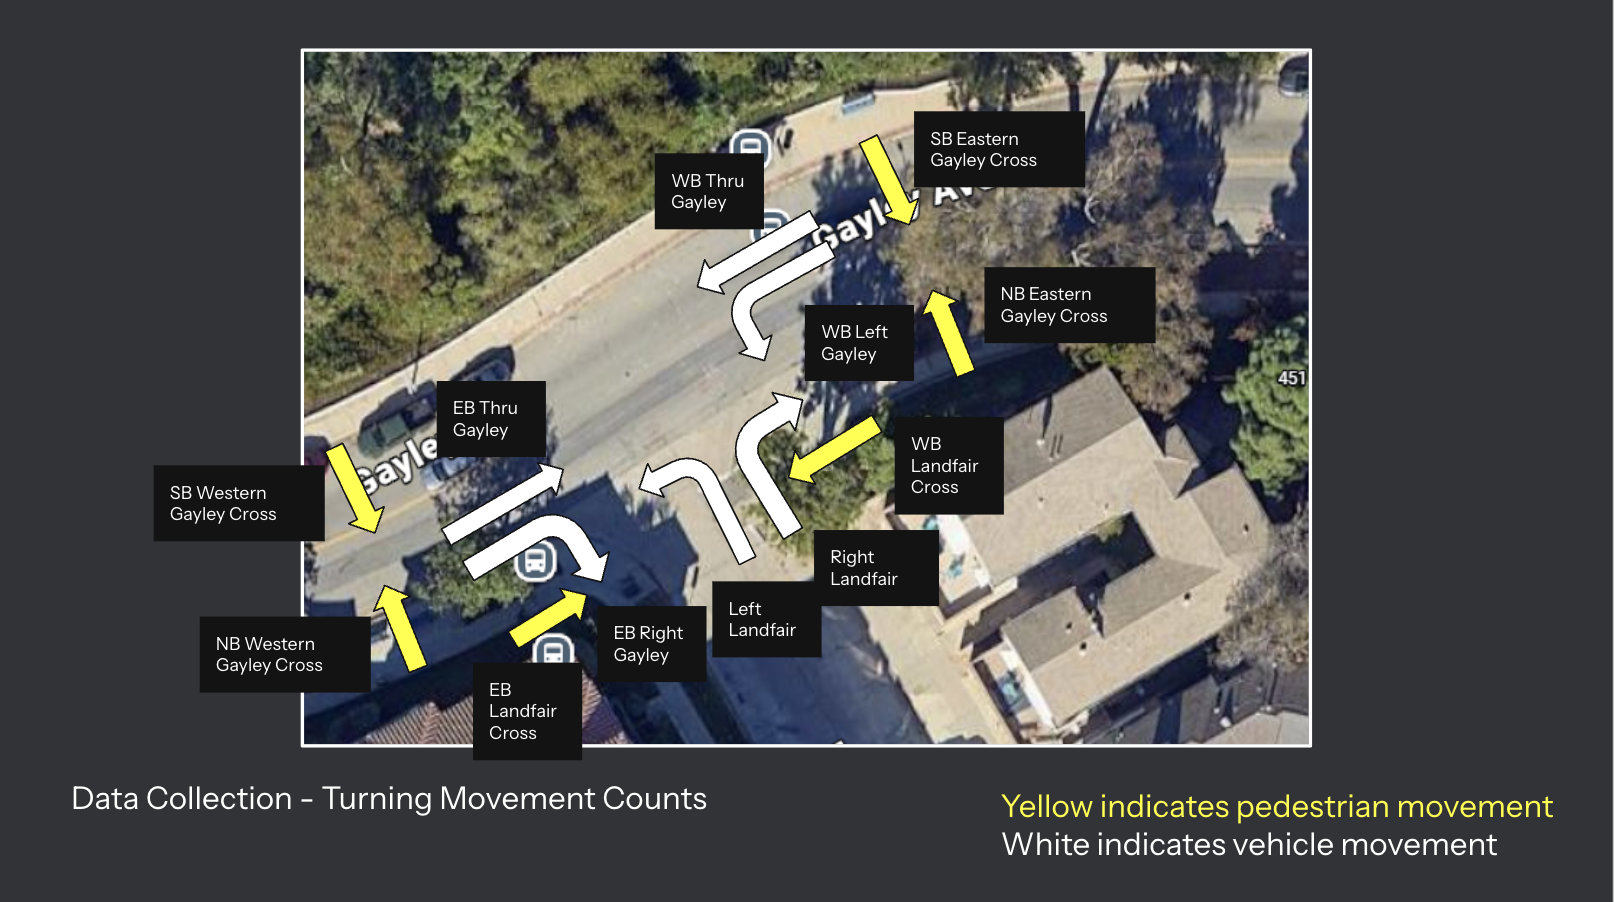

##Conclusion: Reclaiming Spatial Data

This project has tried to demonstrate that urban spaces are never a blank, frictionless canvas but rather a complex, living archive deeply shaped by histocial events, institutional decisions, and structural inequalities. By comparing traditional linear modelling methods with spatial econometric methods to analyze pedestrian footfall, this study uncovers the dangerous sociopolitical biases embedded within seemingly neutral statistical methodologies.

Ultimately, a truly democratic approach to urban planning requires moving past the myth of algorithmic neutrality (Narayanan, 2024). Algorithms and regression equations, no matter how advanced, cannot be arbiters of truth, They are all human designed abstractions that contain specific biases.

If cities want to adopt data-driven methods to serve marginalized populations rather than continue misrepresenting them, they need to actively interrogate whatever models are being used and their individual limitations. Frameworks like SAR are essential technical steps forward, but data metrics need to be balanced alongside qualitative community feedback and a knowledge of the historical implications of specific marginalized communities.

### Bibliography

Anselin, L. (1988). *Spatial econometrics: Methods and models*. Kluwer Academic Publishers.

Anselin, L., Syabri, I., & Kho, Y. (2006). GeoDa: An introduction to spatial data analysis. *Geographical Analysis*, 38(1), 5–22. [https://doi.org/10.1111/j.0016-7363.2005.00671.x](https://doi.org/10.1111/j.0016-7363.2005.00671.x)

Bi-Annual Pedestrian Counts | NYC Open Data. (n.d.). Retrieved June 12, 2026, from [https://data.cityofnewyork.us/Transportation/Bi-Annual-Pedestrian-Counts/cqsj-cfgu/about_data](https://data.cityofnewyork.us/Transportation/Bi-Annual-Pedestrian-Counts/cqsj-cfgu/about_data)

Eubanks, V. (2018). *Automating inequality: How high-tech tools profile, police, and punish the poor* (First edition.). St. Martin’s Press.

Gehl, J. (with Koch, J.). (2011). *Life between buildings: Using public space*. Island Press.

Hacking, I. (1990). The taming of chance. Cambridge University Press.

Narayanan, A. (with Kapoor, S.). (2024). AI snake oil: What artificial intelligence can do, what it can’t, and how to tell the difference. Princeton University Press.


Sevtsuk, A. (2021). Estimating Pedestrian Flows on Street Networks: Revisiting the Betweenness Index. *Journal of the American Planning Association*, 87(4), 512–526. [https://doi.org/10.1080/01944363.2020.1864758](https://doi.org/10.1080/01944363.2020.1864758)

Soja, E. W. (2010). *Seeking spatial justice*. University of Minnesota Press.

Hacking, I. (1990). The taming of chance. Cambridge University Press.

UCLA Institute of Transportation Engineers. (2026). *Gayley/Landfair traffic counts* [Unpublished raw data]. University of California, Los Angeles.

Winner, L. (2017). Do Artifacts Have Politics? In Emerging Technologies: Ethics, Law and Governance (1st ed., pp. 15–30). Routledge. https://doi.org/10.4324/9781003074960-3



